# Step 2: Exploratory Data Analysis (EDA)

**Aim:** look at the cleaned data with tables and charts to find patterns, and write what we learn.

**EDA = Exploratory Data Analysis.** We do not use any machine learning here. We only group, count, average and draw charts.

**Questions we answer**
1. How much energy is generated, and how does it change over the year?
2. Which energy type, plant and region generate the most?
3. How well are the plants used (capacity utilization) and how efficient are they?
4. How does weather change generation?
5. How do downtime, maintenance cost, operating cost and revenue look?
6. Are there unusual days?

**Simple formulas used in this notebook**
- **Maximum energy** of a record = installed capacity (MW) x 4 hours
- **Capacity utilization (%)** = energy generated / maximum energy x 100  (how much of the plant's power we actually used)

## Load the tools and the cleaned data

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# Folder where all the project files are kept
FOLDER = r"D:\RENEWABLE ENERGY PERFORMANCE Project"
if not os.path.exists(FOLDER):
    FOLDER = os.path.dirname(os.getcwd())      # if that folder is not found, use the folder above this notebook

DATA_FOLDER = os.path.join(FOLDER, "data")     # the CSV files are in the "data" folder
if not os.path.exists(DATA_FOLDER):
    DATA_FOLDER = FOLDER                        # if there is no "data" folder, they are in the main folder

cleaned_file = os.path.join(DATA_FOLDER, "cleaned_energy_data.csv")

df = pd.read_csv(cleaned_file)
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Max_Energy"] = df["Installed_Capacity_MW"] * 4

colors = {"Solar": "#F2A900", "Wind": "#2E86AB", "Hydro": "#3BB273"}     # one colour for each energy type
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

print("Rows:", len(df))
df.head()

Rows: 52560


,Record_ID,Plant_ID,Plant_Name,Energy_Type,Region,City,Date,Hour,Energy_Generated_MWh,Installed_Capacity_MW,...,Downtime_Hours,Maintenance_Hours,Plant_Status,Operating_Cost,Maintenance_Cost,Revenue,Efficiency_Percent,Availability_Percent,Month,Max_Energy
0,R000001,P001,Sunridge Solar Park,Solar,West,Jodhpur,2025-01-01,0,0.0,250,...,0.0,0.0,Operational,126573.51,0.0,0.0,92.15,100.0,1,1000
1,R000002,P002,Helios Solar Farm,Solar,South,Tumakuru,2025-01-01,0,0.0,200,...,0.0,0.0,Operational,111413.29,0.0,0.0,90.27,100.0,1,800
2,R000003,P003,Aditya Solar Park,Solar,Central,Rewa,2025-01-01,0,0.0,150,...,0.0,0.0,Operational,85235.46,0.0,0.0,89.41,100.0,1,600
3,R000004,P004,Suryakiran Solar Plant,Solar,South,Ramanathapuram,2025-01-01,0,0.0,180,...,0.0,0.0,Operational,96426.46,0.0,0.0,88.73,100.0,1,720
4,R000005,P005,Dhoop Solar Park,Solar,West,Patan,2025-01-01,0,0.0,120,...,0.0,0.0,Operational,71263.11,0.0,0.0,84.75,100.0,1,480


## 1. Overall numbers

In [3]:
print("Plants                  :", df["Plant_ID"].nunique())
print("Total energy (GWh)      :", round(df["Energy_Generated_MWh"].sum() / 1000, 1))
print("Total revenue (crore)   :", round(df["Revenue"].sum() / 10000000, 1))
print("Operating cost (crore)  :", round(df["Operating_Cost"].sum() / 10000000, 1))
print("Maintenance cost (crore):", round(df["Maintenance_Cost"].sum() / 10000000, 1))
print("Average efficiency (%)  :", round(df["Efficiency_Percent"].mean(), 2))
print("Average utilization (%) :", round(df["Capacity_Utilization"].mean(), 2))

Plants                  : 24
Total energy (GWh)      : 9805.0
Total revenue (crore)   : 3481.3
Operating cost (crore)  : 531.5
Maintenance cost (crore): 18.4
Average efficiency (%)  : 85.76
Average utilization (%) : 28.68


*1 GWh = 1,000 MWh. 1 crore = 10,000,000 rupees (INR).*

## 2. Generation over the year

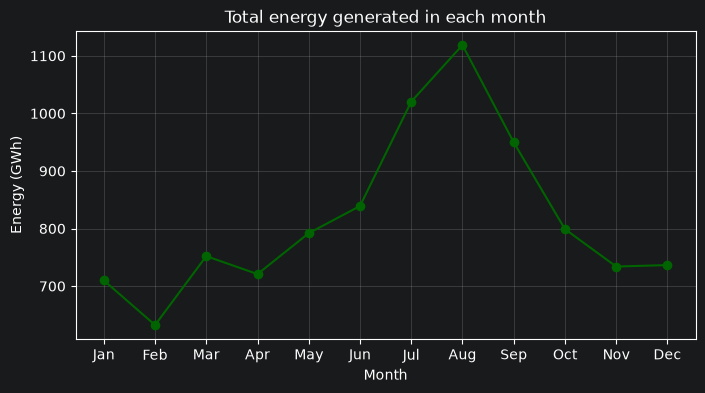

In [4]:
monthly = df.groupby("Month")["Energy_Generated_MWh"].sum() / 1000     # in GWh

monthly.plot(kind="line", marker="o", figsize=(8, 4), color="darkgreen")
plt.xticks(range(1, 13), month_names)
plt.title("Total energy generated in each month")
plt.xlabel("Month")
plt.ylabel("Energy (GWh)")
plt.grid(alpha=0.3)
plt.show()

**What we see:** Generation is lowest in **February (632 GWh)** and highest in **August (1,119 GWh)**. From June to September it is much higher, because the monsoon brings strong winds and heavy rain. February is also the shortest month.

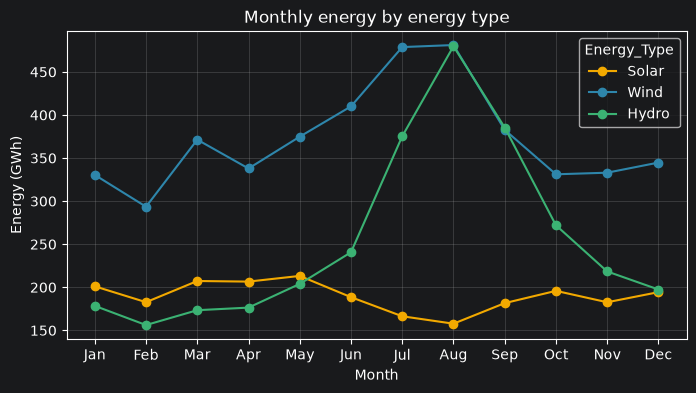

Best month for each type:
Energy_Type
Solar    May
Wind     Aug
Hydro    Aug
dtype: str


In [5]:
by_month_type = df.groupby(["Month", "Energy_Type"])["Energy_Generated_MWh"].sum().unstack() / 1000
by_month_type = by_month_type[["Solar", "Wind", "Hydro"]]

by_month_type.plot(kind="line", marker="o", figsize=(8, 4), color=[colors[t] for t in by_month_type.columns])
plt.xticks(range(1, 13), month_names)
plt.title("Monthly energy by energy type")
plt.xlabel("Month")
plt.ylabel("Energy (GWh)")
plt.grid(alpha=0.3)
plt.show()

print("Best month for each type:")
print(by_month_type.idxmax().map(lambda m: month_names[m - 1]))

**What we see:** Wind and hydro both peak in **August** and fall in the dry months. Solar is steady all year and is highest in **May**, when there are clear skies before the monsoon clouds come.

## 3. Energy type, plant and region

Energy_Type
Wind     45.6
Hydro    31.2
Solar    23.2
Name: Energy_Generated_MWh, dtype: float64


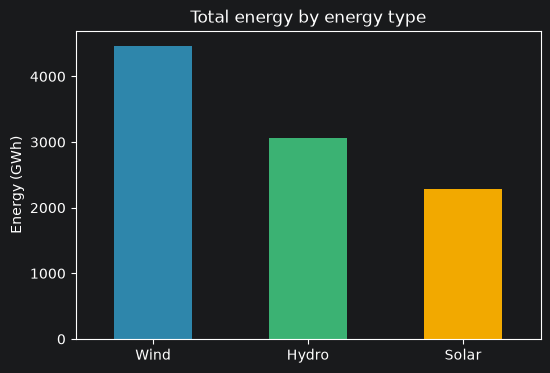

In [6]:
by_type = df.groupby("Energy_Type")["Energy_Generated_MWh"].sum() / 1000
by_type = by_type.sort_values(ascending=False)
print((by_type / by_type.sum() * 100).round(1))

by_type.plot(kind="bar", color=[colors[t] for t in by_type.index], figsize=(6, 4))
plt.title("Total energy by energy type")
plt.xlabel("")
plt.ylabel("Energy (GWh)")
plt.xticks(rotation=0)
plt.show()

**What we see:** **Wind** gives the most energy (4,470 GWh, 45.6%), then **Hydro** (3,057 GWh, 31.2%), then **Solar** (2,278 GWh, 23.2%). Solar has the most plants (10) but gives the least energy, because it works only in the day.

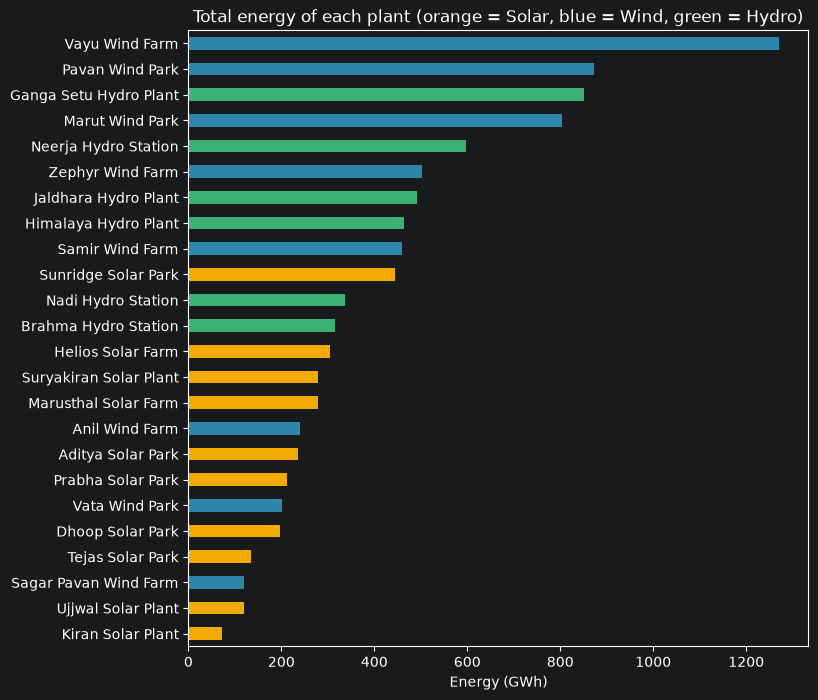

In [7]:
plant = df.groupby(["Plant_Name", "Energy_Type"])["Energy_Generated_MWh"].sum().reset_index()
plant["Energy_GWh"] = plant["Energy_Generated_MWh"] / 1000
plant = plant.sort_values("Energy_GWh")

plant.plot(kind="barh", x="Plant_Name", y="Energy_GWh", legend=False, figsize=(8, 8),
           color=plant["Energy_Type"].map(colors))
plt.title("Total energy of each plant (orange = Solar, blue = Wind, green = Hydro)")
plt.xlabel("Energy (GWh)")
plt.ylabel("")
plt.show()

**What we see:** **Vayu Wind Farm** is the top plant (1,270 GWh), followed by Pavan Wind Park (872 GWh) and Ganga Setu Hydro Plant (851 GWh). The lowest is **Kiran Solar Plant** (72 GWh). The top 5 plants are all wind or hydro.

Region
South      34.2
West       34.0
North      20.7
Central     5.8
East        5.2
Name: Energy_Generated_MWh, dtype: float64


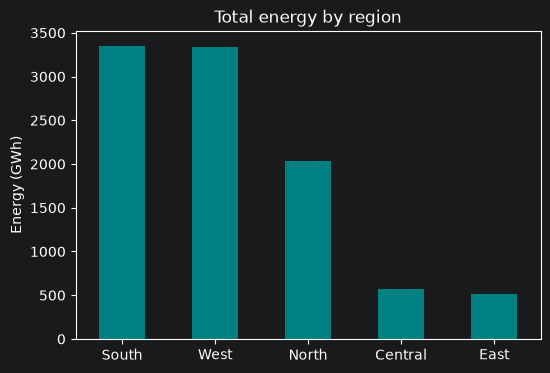

In [8]:
by_region = df.groupby("Region")["Energy_Generated_MWh"].sum().sort_values(ascending=False) / 1000
print((by_region / by_region.sum() * 100).round(1))

by_region.plot(kind="bar", color="teal", figsize=(6, 4))
plt.title("Total energy by region")
plt.xlabel("")
plt.ylabel("Energy (GWh)")
plt.xticks(rotation=0)
plt.show()

**What we see:** **South (34.2%)** and **West (34.0%)** together give two-thirds of all energy. North gives 20.7%. Central and East give only about 5% each.

## 4. Capacity utilization and efficiency
**Capacity utilization** tells how much of a plant's full power was used. A plant with 100 MW that makes 100 MW for 4 hours has 100% utilization.

Energy_Type
Solar    18.18
Wind     40.50
Hydro    37.13
Name: Utilization, dtype: float64


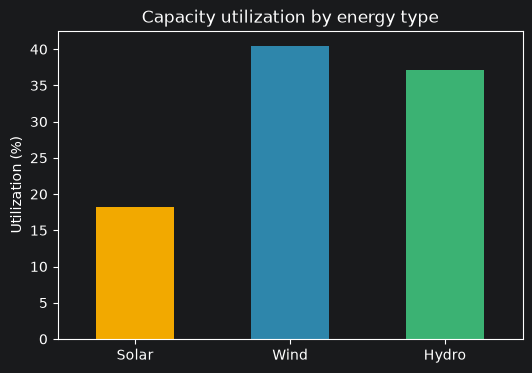

In [9]:
by_type = df.groupby("Energy_Type")[["Energy_Generated_MWh", "Max_Energy"]].sum()
by_type["Utilization"] = by_type["Energy_Generated_MWh"] / by_type["Max_Energy"] * 100
by_type = by_type.loc[["Solar", "Wind", "Hydro"]]
print(by_type["Utilization"].round(2))

by_type["Utilization"].plot(kind="bar", color=[colors[t] for t in by_type.index], figsize=(6, 4))
plt.title("Capacity utilization by energy type")
plt.xlabel("")
plt.ylabel("Utilization (%)")
plt.xticks(rotation=0)
plt.show()

**What we see:** Wind uses **40.5%** of its capacity, hydro **37.1%** and solar only **18.2%**. Solar is low because the sun is not there at night, so solar can never reach a high yearly figure.

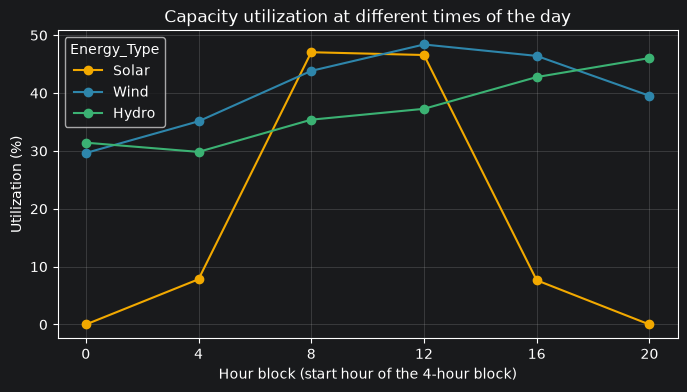

In [10]:
by_hour = df.groupby(["Hour", "Energy_Type"])[["Energy_Generated_MWh", "Max_Energy"]].sum()
by_hour = (by_hour["Energy_Generated_MWh"] / by_hour["Max_Energy"] * 100).unstack()
by_hour = by_hour[["Solar", "Wind", "Hydro"]]

by_hour.plot(kind="line", marker="o", figsize=(8, 4), color=[colors[t] for t in by_hour.columns])
plt.title("Capacity utilization at different times of the day")
plt.xlabel("Hour block (start hour of the 4-hour block)")
plt.ylabel("Utilization (%)")
plt.xticks([0, 4, 8, 12, 16, 20])
plt.grid(alpha=0.3)
plt.show()

**What we see:** Solar is close to **0% at night** (0 and 20) and about **47% in the day** (8 and 12). Wind is highest around noon. Hydro is highest in the evening (46% in the block that starts at 20).

Energy_Type
Solar    84.81
Wind     86.77
Hydro    85.99
Name: Efficiency_Percent, dtype: float64


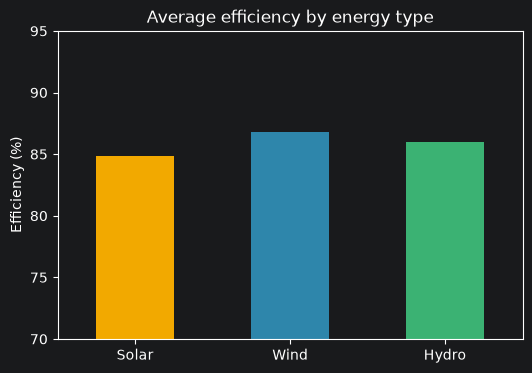

In [11]:
efficiency = df.groupby("Energy_Type")["Efficiency_Percent"].mean().loc[["Solar", "Wind", "Hydro"]]
print(efficiency.round(2))

efficiency.plot(kind="bar", color=[colors[t] for t in efficiency.index], figsize=(6, 4))
plt.title("Average efficiency by energy type")
plt.xlabel("")
plt.ylabel("Efficiency (%)")
plt.ylim(70, 95)
plt.xticks(rotation=0)
plt.show()

**What we see:** Wind (86.8%) and hydro (86.0%) are a little more efficient than solar (84.8%). The difference between types is small, which means efficiency is similar for all plants.

## 5. Weather and generation

### 5.1 Solar: sunlight
We use only the day blocks (start hour 8 and 12), because at night there is no sunlight.

Solar_Irradiance
under 200    14.2
200-400      24.3
400-600      40.6
600-800      50.7
800+         57.0
Name: Capacity_Utilization, dtype: float64


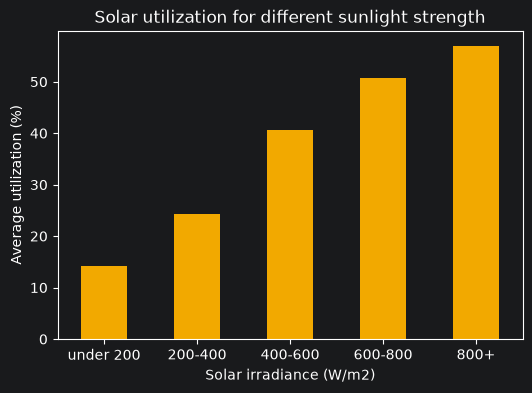

In [12]:
solar_day = df[(df["Energy_Type"] == "Solar") & (df["Hour"].isin([8, 12]))]
bands = pd.cut(solar_day["Solar_Irradiance"], [0, 200, 400, 600, 800, 2000],
               labels=["under 200", "200-400", "400-600", "600-800", "800+"])

solar_by_band = solar_day.groupby(bands, observed=True)["Capacity_Utilization"].mean()
print(solar_by_band.round(1))

solar_by_band.plot(kind="bar", color="#F2A900", figsize=(6, 4))
plt.title("Solar utilization for different sunlight strength")
plt.xlabel("Solar irradiance (W/m2)")
plt.ylabel("Average utilization (%)")
plt.xticks(rotation=0)
plt.show()

**What we see:** When sunlight goes from under 200 to over 800 W/m2, solar utilization goes from **14% to 57%**. Sunlight is the main driver of solar energy.

### 5.2 Wind: wind speed

Wind_Speed_kmh
under 10     0.0
10-20        1.1
20-30       14.2
30-40       57.2
40-50       83.1
50+         78.5
Name: Capacity_Utilization, dtype: float64


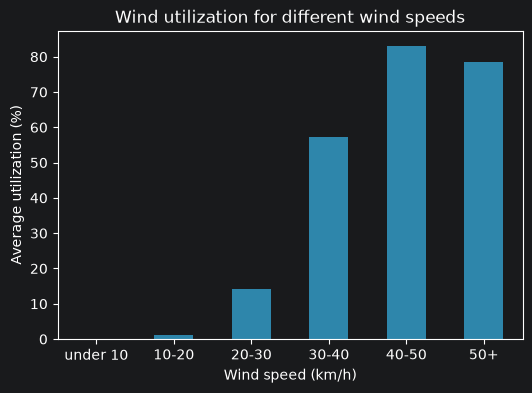

In [13]:
wind = df[df["Energy_Type"] == "Wind"]
bands = pd.cut(wind["Wind_Speed_kmh"], [-1, 10, 20, 30, 40, 50, 200],
               labels=["under 10", "10-20", "20-30", "30-40", "40-50", "50+"])

wind_by_band = wind.groupby(bands, observed=True)["Capacity_Utilization"].mean()
print(wind_by_band.round(1))

wind_by_band.plot(kind="bar", color="#2E86AB", figsize=(6, 4))
plt.title("Wind utilization for different wind speeds")
plt.xlabel("Wind speed (km/h)")
plt.ylabel("Average utilization (%)")
plt.xticks(rotation=0)
plt.show()

**What we see:** Below 20 km/h the turbines make almost nothing (0% to 1%). Between 30 and 50 km/h utilization jumps from **57% to 83%**. Above 50 km/h it does not grow any more (78.5%), because turbines have a top limit.

### 5.3 Hydro: rainfall

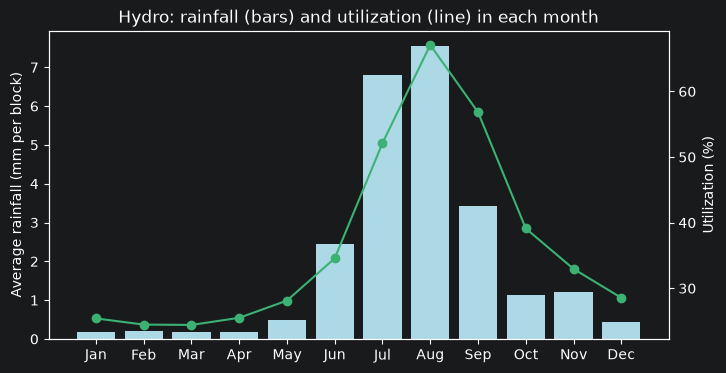

In [14]:
hydro = df[df["Energy_Type"] == "Hydro"]
hydro_month = hydro.groupby("Month")[["Rainfall_mm", "Capacity_Utilization"]].mean()

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(hydro_month.index, hydro_month["Rainfall_mm"], color="lightblue")
ax1.set_ylabel("Average rainfall (mm per block)")
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(month_names)
ax2 = ax1.twinx()
ax2.plot(hydro_month.index, hydro_month["Capacity_Utilization"], color="#3BB273", marker="o")
ax2.set_ylabel("Utilization (%)")
plt.title("Hydro: rainfall (bars) and utilization (line) in each month")
plt.show()

**What we see:** Rainfall is highest in **July and August**, and hydro utilization is highest in **August (67%)**. Rain fills the dams, so hydro plants make the most energy in the rainy months and a little after them (September 57%).

### 5.4 How strong is the link? (correlation)
Correlation is a number from -1 to +1. Near +1 means 'when one goes up, the other goes up too'. Near 0 means no clear link.

In [15]:
solar_all = df[df["Energy_Type"] == "Solar"]
wind_all = df[df["Energy_Type"] == "Wind"]
hydro_all = df[df["Energy_Type"] == "Hydro"]

print("Solar: irradiance vs utilization :", round(solar_all["Solar_Irradiance"].corr(solar_all["Capacity_Utilization"]), 2))
print("Wind : wind speed vs utilization :", round(wind_all["Wind_Speed_kmh"].corr(wind_all["Capacity_Utilization"]), 2))
print("Hydro: rainfall vs utilization   :", round(hydro_all["Rainfall_mm"].corr(hydro_all["Capacity_Utilization"]), 2))

Solar: irradiance vs utilization : 0.97
Wind : wind speed vs utilization : 0.74
Hydro: rainfall vs utilization   : 0.3


**What we see:** Solar has a very strong link with sunlight (**0.97**). Wind has a strong link with wind speed (**0.74**). Hydro has a weaker link with rainfall on the same day (**0.30**), because dams store the water and release it later.

## 6. Downtime and generation

Plant_Status
Operational          197.6
Partial Outage       114.1
Under Maintenance     53.7
Shutdown               0.0
Name: Energy_Generated_MWh, dtype: float64

Plant_Status
Operational          90.0
Partial Outage        6.1
Under Maintenance     3.2
Shutdown              0.7
Name: proportion, dtype: float64


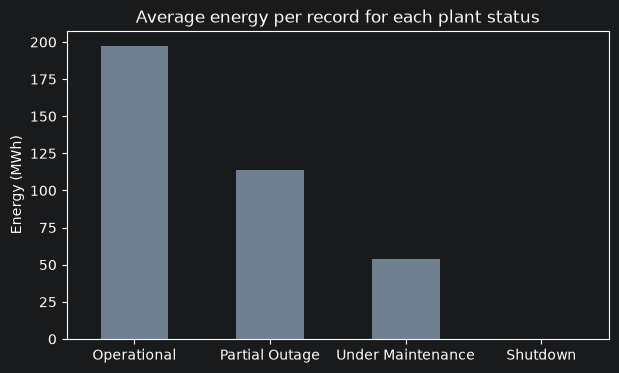

In [16]:
status_energy = df.groupby("Plant_Status")["Energy_Generated_MWh"].mean().sort_values(ascending=False)
print(status_energy.round(1))
print()
print((df["Plant_Status"].value_counts(normalize=True) * 100).round(1))

status_energy.plot(kind="bar", color="slategray", figsize=(7, 4))
plt.title("Average energy per record for each plant status")
plt.xlabel("")
plt.ylabel("Energy (MWh)")
plt.xticks(rotation=0)
plt.show()

**What we see:** Operational blocks give about **198 MWh** on average. Partial outage gives 114 MWh, under maintenance 54 MWh and shutdown **0 MWh**. About 90% of blocks are operational, so most losses come from the other 10%.

Plant_Name
Sagar Pavan Wind Farm    9.1
Kiran Solar Plant        8.7
Vata Wind Park           7.8
Anil Wind Farm           7.1
Nadi Hydro Station       6.1
Tejas Solar Park         5.7
Zephyr Wind Farm         5.7
Pavan Wind Park          5.4
Samir Wind Farm          5.0
Dhoop Solar Park         4.6
Name: Downtime_Rate, dtype: float64


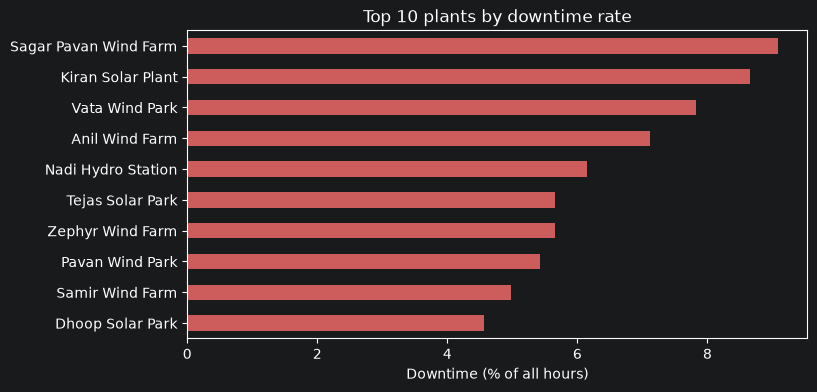

In [17]:
downtime = df.groupby("Plant_Name").agg(Downtime_Hours=("Downtime_Hours", "sum"), Records=("Record_ID", "count"))
downtime["Downtime_Rate"] = downtime["Downtime_Hours"] / (downtime["Records"] * 4) * 100
downtime = downtime.sort_values("Downtime_Rate", ascending=False).head(10)
print(downtime["Downtime_Rate"].round(1))

downtime["Downtime_Rate"].sort_values().plot(kind="barh", color="indianred", figsize=(8, 4))
plt.title("Top 10 plants by downtime rate")
plt.xlabel("Downtime (% of all hours)")
plt.ylabel("")
plt.show()

**What we see:** **Sagar Pavan Wind Farm (9.1%)**, Kiran Solar Plant (8.7%), Vata Wind Park (7.8%), Anil Wind Farm (7.1%) and Nadi Hydro Station (6.1%) have the highest downtime. These plants need maintenance planning first.

## 7. Cost and revenue

             Operating_Cost  Maintenance_Cost  Revenue
Energy_Type                                           
Solar                 180.9               4.4    704.3
Wind                  251.2               9.8   1496.8
Hydro                  99.4               4.2   1280.2


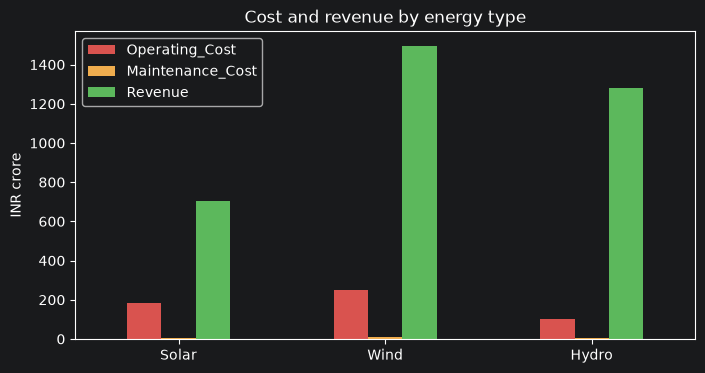

In [18]:
money = df.groupby("Energy_Type")[["Operating_Cost", "Maintenance_Cost", "Revenue"]].sum() / 10000000    # in crore
money = money.loc[["Solar", "Wind", "Hydro"]]
print(money.round(1))

money.plot(kind="bar", figsize=(8, 4), color=["#d9534f", "#f0ad4e", "#5cb85c"])
plt.title("Cost and revenue by energy type")
plt.xlabel("")
plt.ylabel("INR crore")
plt.xticks(rotation=0)
plt.show()

In [19]:
energy = df.groupby("Energy_Type")["Energy_Generated_MWh"].sum()
cost_per_mwh = (money["Operating_Cost"] + money["Maintenance_Cost"]) * 10000000 / energy
profit_margin = (money["Revenue"] - money["Operating_Cost"] - money["Maintenance_Cost"]) / money["Revenue"] * 100

print("Cost per MWh (INR):")
print(cost_per_mwh.round(0))
print()
print("Profit margin (%):")
print(profit_margin.round(1))

Cost per MWh (INR):
Energy_Type
Hydro    339.0
Solar    814.0
Wind     584.0
dtype: float64

Profit margin (%):
Energy_Type
Solar    73.7
Wind     82.6
Hydro    91.9
dtype: float64


**What we see:** Wind earns the most money (**1,497 crore**) and hydro is second (1,280 crore). Hydro is the cheapest to run (**INR 339 per MWh**) and has the best profit margin (**91.9%**). Solar costs the most per MWh (**INR 814**) and has the lowest margin (**73.7%**). Wind plants also have the highest maintenance cost: 9.8 crore, which is more than solar (4.4 crore) or hydro (4.3 crore).

## 8. Availability
**Availability** = share of time the plant was ready to work. Availability = (4 - downtime hours) / 4 x 100.

Lowest 3 : {'Sagar Pavan Wind Farm': 90.9, 'Kiran Solar Plant': 91.3, 'Vata Wind Park': 92.2}
Highest 2: {'Himalaya Hydro Plant': 97.1, 'Sunridge Solar Park': 97.3}


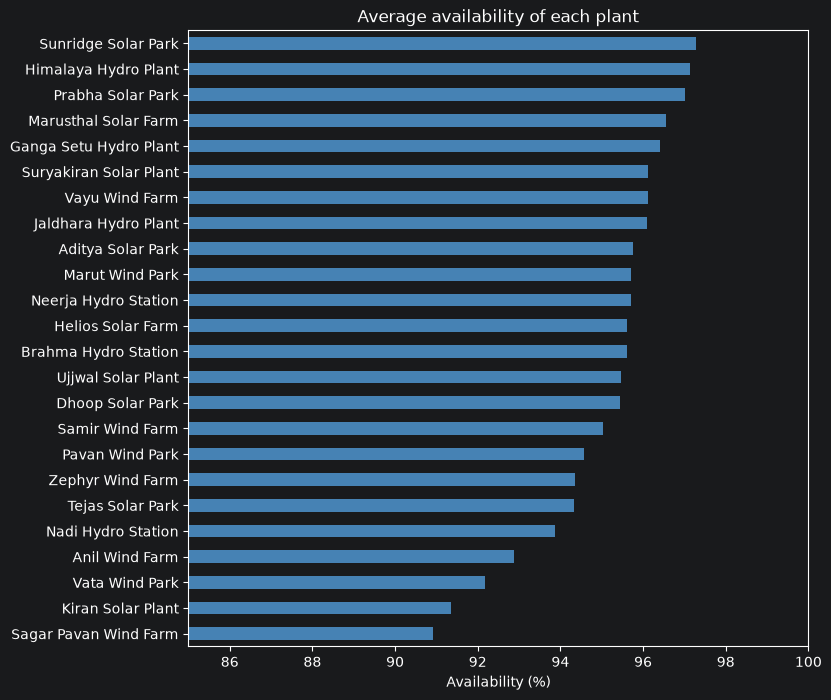

In [20]:
availability = df.groupby("Plant_Name")["Availability_Percent"].mean().sort_values()
print("Lowest 3 :", availability.head(3).round(1).to_dict())
print("Highest 2:", availability.tail(2).round(1).to_dict())

availability.plot(kind="barh", color="steelblue", figsize=(8, 8))
plt.title("Average availability of each plant")
plt.xlabel("Availability (%)")
plt.ylabel("")
plt.xlim(85, 100)
plt.show()

**What we see:** Every plant is above 90%. The best are **Sunridge Solar Park (97.3%)** and Himalaya Hydro Plant (97.1%). The lowest are Sagar Pavan Wind Farm (90.9%) and Kiran Solar Plant (91.3%). The low availability plants are the same plants that have high downtime.

## 9. Unusual days
For each day we add the energy of all plants. Then we compare it with the average day of the **same month** (to remove the season effect). A ratio near 1 is a normal day. A low ratio is a weak day.

5 weakest days (ratio to the month average):
Date
2025-04-01    0.73
2025-05-03    0.74
2025-10-24    0.80
2025-12-08    0.80
2025-06-14    0.81
Name: Energy_Generated_MWh, dtype: float64


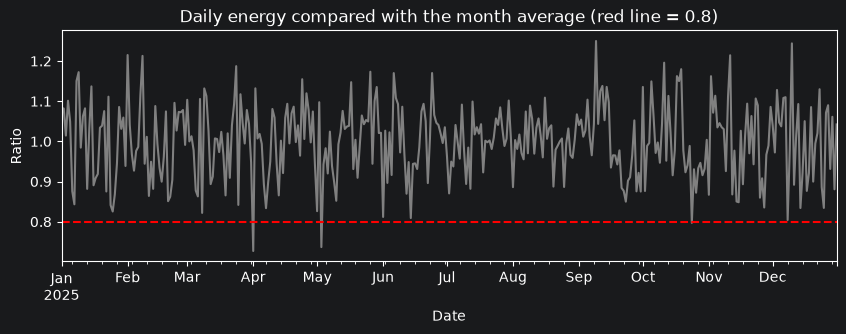

In [21]:
daily = df.groupby("Date")["Energy_Generated_MWh"].sum()
month_average = daily.groupby(daily.index.month).transform("mean")
ratio = (daily / month_average).sort_values()

print("5 weakest days (ratio to the month average):")
print(ratio.head(5).round(2))

(daily / month_average).plot(figsize=(10, 3), color="gray")
plt.axhline(0.8, color="red", linestyle="--")
plt.title("Daily energy compared with the month average (red line = 0.8)")
plt.ylabel("Ratio")
plt.show()

**What we see:** The weakest days are **1 April (0.73)**, **3 May (0.74)** and 24 October (0.80). These days were about a quarter below a normal day of that month. The reason can be low wind, cloud, or many plants stopped on the same day, so these days should be checked. No day is very far from normal, so the data has no big shock.

## 10. Summary of what we learned
1. **Wind** is the biggest source (45.6% of energy). Hydro is second (31.2%) and solar is third (23.2%).
2. **August** is the best month. **February** is the weakest month.
3. **South and West** regions give 68% of all energy.
4. **Vayu Wind Farm** is the best plant. **Kiran Solar Plant** is the weakest.
5. Solar depends on sunlight (correlation 0.97). Wind depends on wind speed (0.74). Hydro depends on the rainy season.
6. Wind and hydro use about 40% and 37% of their capacity. Solar uses only 18%.
7. Hydro is the cheapest to run (INR 339 per MWh) and gives the best profit margin (91.9%).
8. Five plants have downtime above 6%: Sagar Pavan Wind, Kiran Solar, Vata Wind, Anil Wind and Nadi Hydro. These should be maintained first.